Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'DESeq2', 'airway', 'EnhancedVolcano'

also installing the dependencies ‘XVector’, ‘formatR’, ‘abind’, ‘SparseArray’, ‘lambda.r’, ‘futile.options’, ‘Seqinfo’, ‘S4Arrays’, ‘DelayedArray’, ‘futile.logger’, ‘snow’, ‘BH’, ‘S4Vectors’, ‘IRanges’, ‘GenomicRanges’, ‘SummarizedExperiment’, ‘BiocGenerics’, ‘Biobase’, ‘BiocParallel’, ‘matrixStats’, ‘locfit’, ‘MatrixGenerics’, ‘RcppArmadillo’, ‘ggrepel’


Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from 

[1] "Top 5 Differentially Expressed Genes:"
                  baseMean log2FoldChange      lfcSE     stat        pvalue
ENSG00000152583   997.4398       4.602526 0.21177076 21.73353 9.890364e-105
ENSG00000148175 11193.7188       1.451466 0.08482489 17.11132  1.221982e-65
ENSG00000179094   776.5967       3.183857 0.20151544 15.79957  3.132468e-56
ENSG00000134686  2737.9820       1.387141 0.09158425 15.14607  8.044039e-52
ENSG00000125148  3656.2528       2.203439 0.14740866 14.94782  1.609239e-50
                         padj
ENSG00000152583 1.838124e-100
ENSG00000148175  1.135527e-61
ENSG00000179094  1.940564e-52
ENSG00000134686  3.737462e-48
ENSG00000125148  5.981541e-47


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the EnhancedVolcano package.
  Please report the issue to the authors.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the EnhancedVolcano package.
  Please report the issue to the authors.”


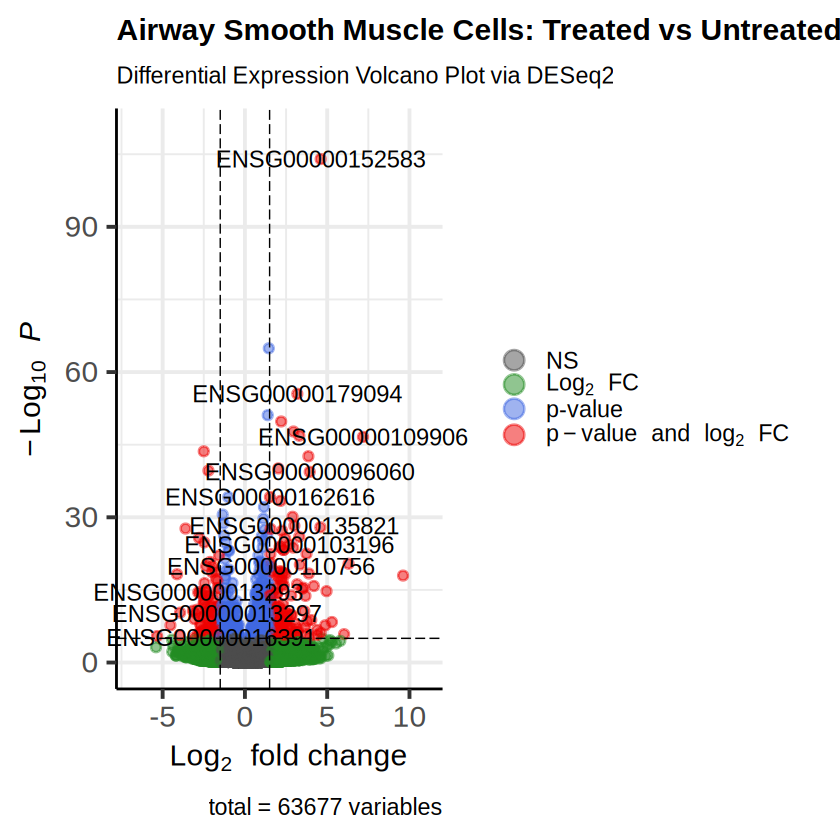

In [1]:
# 1. Install the Bioconductor manager and standard transcriptomic packages
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")
BiocManager::install(c("DESeq2", "airway", "EnhancedVolcano"), update=FALSE, ask=FALSE)

# 2. Load the core biological libraries
library(DESeq2)
library(airway)
library(EnhancedVolcano)

# 3. Fetch the public RNA-Seq dataset (Human airway smooth muscle cells treated with dexamethasone)
data("airway")
se <- airway

# 4. Construct the DESeq2 data object from the experiment counts
dds <- DESeqDataSet(se, design = ~ dex)

# 5. Execute the differential expression statistical engine
dds <- DESeq(dds)

# 6. Extract statistical significance results (comparing treated vs untreated cohorts)
res <- results(dds, contrast=c("dex", "trt", "untrt"))
res_df <- as.data.frame(res)

# 7. Print the top 5 most significantly altered genes to verify success
print("Top 5 Differentially Expressed Genes:")
print(head(res_df[order(res_df$pvalue), ], 5))

# 8. Render a publication-ready Volcano Plot to isolate driver genes
EnhancedVolcano(res,
    lab = rownames(res),
    x = 'log2FoldChange',
    y = 'pvalue',
    pCutoff = 10e-6,
    FCcutoff = 1.5,
    title = 'Airway Smooth Muscle Cells: Treated vs Untreated',
    subtitle = 'Differential Expression Volcano Plot via DESeq2',
    legendPosition = 'right')
